<a href="https://colab.research.google.com/github/madhaviramkumar123-arch/rookie-go/blob/main/movie_sentiment_classifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# The Idea: Movie Review Sentiment Classifier
##### This model predicts whether a movie review expresses positive or negative opinions based on words alone. Film studios, streaming platforms, companies recieve tens of thousands of reviews and can't read them all. Automatic sentiment analysis summarizes audience opinions at scale.


### Data Preparation

In [25]:
import pandas as pd
import matplotlib.pyplot as plt
import nltk
from nltk.corpus import movie_reviews
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report)

In [26]:
nltk.download("movie_reviews")

data = [(movie_reviews.raw(fid), label)
        for label in movie_reviews.categories()
        for fid in movie_reviews.fileids(label)]

df = pd.DataFrame(data, columns=["review", "sentiment"])
df.head()

[nltk_data] Downloading package movie_reviews to /root/nltk_data...
[nltk_data]   Package movie_reviews is already up-to-date!


,review,sentiment
0,"plot : two teen couples go to a church party ,...",neg
1,the happy bastard's quick movie review \ndamn ...,neg
2,it is movies like these that make a jaded movi...,neg
3,""" quest for camelot "" is warner bros . ' firs...",neg
4,synopsis : a mentally unstable man undergoing ...,neg


In [27]:
print(df.shape)
print(df.isnull().sum())
print("Duplicate reviews:", df.duplicated().sum())
print(df["sentiment"].value_counts())

(2000, 2)
review       0
sentiment    0
dtype: int64
Duplicate reviews: 0
sentiment
neg    1000
pos    1000
Name: count, dtype: int64


##### There are 2000 reviews in this dataset of two columns (review and sentiment) with 1000 having negative sentiment and 1000 having positive sentiment. It's a perfect balance, so accuracy is a fair metric and a random guess would score 50%. There are no missing values or repeated reviews.

In [28]:
print(df["review"][0][:500])
df["review"].str.split().str.len().describe()

plot : two teen couples go to a church party , drink and then drive . 
they get into an accident . 
one of the guys dies , but his girlfriend continues to see him in her life , and has nightmares . 
what's the deal ? 
watch the movie and " sorta " find out . . . 
critique : a mind-fuck movie for the teen generation that touches on a very cool idea , but presents it in a very bad package . 
which is what makes this review an even harder one to write , since i generally applaud films which attempt


,review
count,2000.00000
mean,746.34050
std,328.42529
min,17.00000
25%,526.75000
50%,696.50000
75%,904.00000
max,2678.00000


In [29]:
y = (df["sentiment"] == "pos").astype(int)   # 1 = positive, 0 = negative
X = df["review"]                              # raw text

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(len(X_train), len(X_test))

1600 400


##### The target is 1 for positive sentiment and 0 for negative. The features are the raw review text in the first column. The data is split 80/20 that is 1600 reviews for training and 400 purposefully held back for testing. Text will be converted to numbers using TD-IDF.  

### Model Building

In [30]:
vec = TfidfVectorizer(stop_words="english", max_features=5000)
X_train_tfidf = vec.fit_transform(X_train)
X_test_tfidf = vec.transform(X_test)

tree = DecisionTreeClassifier(max_depth=20, random_state=42)
tree.fit(X_train_tfidf, y_train)

knn = KNeighborsClassifier(n_neighbors=5, metric="cosine")
knn.fit(X_train_tfidf, y_train)

KNeighborsClassifier(metric='cosine')

### Evaluation

In [31]:
tree_pred = tree.predict(X_test_tfidf)
knn_pred = knn.predict(X_test_tfidf)

print("Decision Tree accuracy:", accuracy_score(y_test, tree_pred))
print("KNN accuracy:", accuracy_score(y_test, knn_pred))
print("Baseline (random guess):", 0.5)

Decision Tree accuracy: 0.6725
KNN accuracy: 0.66
Baseline (random guess): 0.5


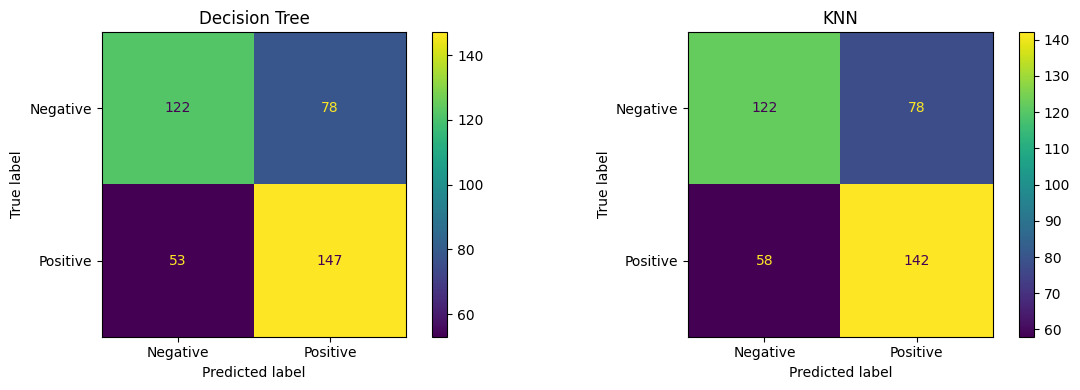

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, pred, name in zip(axes, [tree_pred, knn_pred], ["Decision Tree", "KNN"]):
    cm = confusion_matrix(y_test, pred)
    ConfusionMatrixDisplay(cm, display_labels=["Negative", "Positive"]).plot(ax=ax)
    ax.set_title(name)
plt.tight_layout()
plt.show()

In [33]:
print("Decision Tree\n", classification_report(y_test, tree_pred, target_names=["Negative", "Positive"]))
print("KNN\n", classification_report(y_test, knn_pred, target_names=["Negative", "Positive"]))

Decision Tree
               precision    recall  f1-score   support

    Negative       0.70      0.61      0.65       200
    Positive       0.65      0.73      0.69       200

    accuracy                           0.67       400
   macro avg       0.68      0.67      0.67       400
weighted avg       0.68      0.67      0.67       400

KNN
               precision    recall  f1-score   support

    Negative       0.68      0.61      0.64       200
    Positive       0.65      0.71      0.68       200

    accuracy                           0.66       400
   macro avg       0.66      0.66      0.66       400
weighted avg       0.66      0.66      0.66       400



In [34]:
samples = [
    "An absolutely brilliant film with wonderful acting",
    "Boring, awful acting with a terrible plot",
    "Not bad at all, surprised that I enjoyed it"
]
print("Tree:", tree.predict(vec.transform(samples)))
print("KNN: ", knn.predict(vec.transform(samples)))

Tree: [1 0 0]
KNN:  [1 0 0]


### Conclusion

##### Both the models Decision Tree and KNN beat the 50% random guess baseline but not really accurate on their own either. The lower values are mostly because the two models are weak when it comes to text. Additionally, TD-IDF counts words but neglects word order, thus 'not bad' would be marked as bad (negative sentiment) and 'not good' as 'good'. The average review is also rather long, with winded explanations on cast, plot devices and director. The buzzwords might be detected in parts of the review that aren't an opinion on the movie itself. Further, 1600 reviews is too little for language. More data helps texts models a lot.
#####Decision Tree has an accuracy of 67.25% and KNN has an accuracy if 66%. Making Tree slightly better. Both models over-predicted 'positive' with negative reviews harder to identify (recall of only 0.61)
##### I have learnt that TD-IDF converts text into numbers, also how to read a confusion matrix and recall. I've also learnt that these models counting words struggle with negation such as 'not bad'. My next step to improvise would be to try models such as Logistic Regression and Naive Bayes which work better with text.